# Insider Trading Signals from SEC Form 4: Abnormal Returns after Purchases and Sales by Officers and Directors, Clusters and Roles, and a Gradient-Boosting Filter Tested Out of Time

Corporate insiders (officers, directors and 10% owners) must report their trades in their company's shares on **Form 4** within two business days. The ethics part of the CFA curriculum draws a sharp line: trading on **material non-public information** is prohibited, but insiders' legal trades are public information once filed, and a long literature (Seyhun, 1986; Lakonishok and Lee, 2001; Cohen, Malloy and Pomorski, 2012) finds that insider **purchases** are followed by abnormal returns, while sales, often for diversification or liquidity, say much less.

This notebook tests that with the SEC's structured Form 4 data for 2016–2025:

1. **Event study:** abnormal returns (stock minus the S&P 500 ETF) over 5, 20, 60 and 120 trading days after the filing becomes public, for open-market purchases and sales.
2. **Which purchases matter:** by role (CEO or CFO, director, other officer), size, **clusters** of several insiders buying together, and whether the stock had fallen before (contrarian buying).
3. **A machine-learning filter:** LightGBM ranks purchases by expected 60-day abnormal return, trained on 2016–2021 and tested on 2022–2025, against simple rules a reader of Form 4s would use.

**Data.** SEC Insider Transactions Data Sets (Forms 3, 4 and 5, quarterly, 2016–2025: submissions, reporting owners, non-derivative transactions); Yahoo Finance (daily prices of the issuers and the S&P 500 ETF).

**Methods.** Event study with market-adjusted abnormal returns, t-tests clustered by date, cross-sectional regressions, LightGBM regression, out-of-time portfolio sorts.

**Key output.** Average abnormal returns after insider purchases and sales; which purchase characteristics predict them; and whether an ML filter beats simple rules after the information is public.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import zipfile
import lightgbm as lgb
import statsmodels.formula.api as smf
import yfinance as yf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
QUARTERS = [
    f"{y}q{q}"
    for y in range(2016, 2026)
    for q in range(1, 5)
    if (y, q) <= (2025, 2)
]
MIN_VALUE = 10_000  # USD per insider-day
MIN_PRICE = 2.0
HORIZONS = [5, 20, 60, 120]
TRAIN_LAST = 2021

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Form 4 transactions

From each quarterly data set: Form 4 filings, their reporting owners (role and title) and non-derivative transactions with code **P** (open-market or private purchase) or **S** (open-market or private sale). Trades by the same insider in the same company on the same filing are added up; the event date is the **filing date**, when the trade becomes public.

In [3]:
def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=600)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def role(rel, title):
    rel, title = str(rel).lower(), str(title).lower()
    if re.search(r"chief executive|\bceo\b|president", title):
        return "CEO"
    if re.search(r"chief financial|\bcfo\b|treasurer", title):
        return "CFO"
    if "officer" in rel:
        return "other officer"
    if "director" in rel:
        return "director"
    if "tenpercent" in rel.replace(" ", "").replace("%", "percent"):
        return "10% owner"
    return "other"


def fetch_form4():
    out = []
    for q in QUARTERS:
        r = sec_get(
            f"https://www.sec.gov/files/structureddata/data/insider-transactions-data-sets/{q}_form345.zip"
        )
        if r is None:
            continue
        z = zipfile.ZipFile(io.BytesIO(r.content))
        # the 10b5-1 flag exists from 2023
        sub = pd.read_csv(
            z.open("SUBMISSION.tsv"),
            sep="\t",
            dtype=str,
            usecols=lambda c: c in {
                "ACCESSION_NUMBER",
                "FILING_DATE",
                "DOCUMENT_TYPE",
                "ISSUERCIK",
                "ISSUERTRADINGSYMBOL",
                "AFF10B5ONE",
            },
        )
        sub = sub[sub.DOCUMENT_TYPE == "4"]
        if "AFF10B5ONE" not in sub:
            sub["AFF10B5ONE"] = np.nan
        own = pd.read_csv(
            z.open("REPORTINGOWNER.tsv"),
            sep="\t",
            dtype=str,
            usecols=[
                "ACCESSION_NUMBER",
                "RPTOWNERCIK",
                "RPTOWNER_RELATIONSHIP",
                "RPTOWNER_TITLE",
            ],
        )
        own = own.drop_duplicates("ACCESSION_NUMBER")
        tr = pd.read_csv(
            z.open("NONDERIV_TRANS.tsv"),
            sep="\t",
            dtype=str,
            usecols=[
                "ACCESSION_NUMBER",
                "TRANS_DATE",
                "TRANS_CODE",
                "TRANS_SHARES",
                "TRANS_PRICEPERSHARE",
                "SHRS_OWND_FOLWNG_TRANS",
            ],
        )
        tr = tr[tr.TRANS_CODE.isin(["P", "S"])]
        d = tr.merge(sub, on="ACCESSION_NUMBER").merge(
            own, on="ACCESSION_NUMBER"
        )
        out.append(d)
        time.sleep(0.2)
    return pd.concat(out, ignore_index=True)


t0 = time.time()
RAW = cached("form4_purchases_sales", fetch_form4, max_age_hours=24 * 90)
T = RAW.copy()
for c in ["TRANS_SHARES", "TRANS_PRICEPERSHARE", "SHRS_OWND_FOLWNG_TRANS"]:
    T[c] = pd.to_numeric(T[c], errors="coerce")
T["value"] = T.TRANS_SHARES * T.TRANS_PRICEPERSHARE
T["filed"] = pd.to_datetime(T.FILING_DATE, format="mixed", errors="coerce")
T = T.dropna(subset=["filed", "value", "ISSUERTRADINGSYMBOL"])
T["ticker"] = (
    T.ISSUERTRADINGSYMBOL.str.upper()
    .str.strip()
    .str.replace(".", "-", regex=False)
)
T["role"] = [
    role(r, t) for r, t in zip(T.RPTOWNER_RELATIONSHIP, T.RPTOWNER_TITLE)
]
EV = (
    T.groupby(["ACCESSION_NUMBER", "TRANS_CODE"])
    .agg(
        filed=("filed", "first"),
        ticker=("ticker", "first"),
        issuer=("ISSUERCIK", "first"),
        owner=("RPTOWNERCIK", "first"),
        role=("role", "first"),
        value=("value", "sum"),
        shares=("TRANS_SHARES", "sum"),
        owned_after=("SHRS_OWND_FOLWNG_TRANS", "last"),
        price=("TRANS_PRICEPERSHARE", "mean"),
        plan=(
            "AFF10B5ONE",
            lambda v: (v.astype(str).str.lower().isin(["1", "true"])).any(),
        ),
    )
    .reset_index()
)
EV = EV[
    (EV.value >= MIN_VALUE) & (EV.price >= MIN_PRICE) & (EV.role != "other")
]
EV["stake_change"] = (
    EV.shares
    / (
        EV.owned_after - np.where(EV.TRANS_CODE == "P", EV.shares, -EV.shares)
    ).clip(lower=1)
).clip(0, 10)
print(
    f"{len(RAW):,} purchase and sale lines in {len(QUARTERS)} quarterly data"
    f" sets · {len(EV):,} insider-filing events above USD 10,000"
    f" ({(EV.TRANS_CODE == 'P').sum():,} purchases,"
    f" {(EV.TRANS_CODE == 'S').sum():,} sales), {EV.ticker.nunique():,}"
    f" tickers · {time.time() - t0:.0f} s"
)
EV.groupby(["TRANS_CODE", "role"]).agg(
    events=("value", "size"), median_value=("value", "median")
).unstack(0).round(0)

1,085,769 purchase and sale lines in 38 quarterly data sets · 418,013 insider-filing events above USD 10,000 (87,380 purchases, 330,633 sales), 7,933 tickers · 115 s


events         median_value             
TRANS_CODE         P       S            P            S
role                                                  
10% owner      17158   20861   480,783.00 1,687,508.00
CEO            17339   82224    85,047.00   637,639.00
CFO             4364   27743    49,692.00   295,390.00
director       39371   72949    72,500.00   308,224.00
other officer   9148  126856    51,500.00   263,918.00

## 3. Event study

Entry is the close of the first trading day **after** the filing date, so only public information is used. The abnormal return over *h* trading days is the stock's buy-and-hold return minus the S&P 500 ETF's over the same days. Prices come from Yahoo for tickers that still trade (companies delisted since are missing, a survivorship bias discussed at the end). Purchases are studied for every ticker with a purchase; sales for the same tickers.

In [4]:
tick_p = sorted(EV[EV.TRANS_CODE == "P"].ticker.unique())
PX = cached(
    "yahoo_daily_insiders",
    lambda: yf.download(
        tick_p + ["SPY"],
        start="2015-12-01",
        interval="1d",
        auto_adjust=True,
        progress=False,
        threads=True,
    )["Close"],
    max_age_hours=24 * 30,
)
PX.index = pd.to_datetime(PX.index)
dates = PX.index
pos = np.searchsorted(dates.values, (EV.filed + pd.Timedelta(days=1)).values)
EV["i0"] = pos
spy = PX.SPY.to_numpy()
cols = {t: i for i, t in enumerate(PX.columns)}
P = PX.to_numpy()
for h in HORIZONS + [-20, -120]:
    ar = np.full(len(EV), np.nan)
    for k, (t, i0) in enumerate(zip(EV.ticker, EV.i0)):
        c = cols.get(t)
        if c is None:
            continue
        a, b = (i0, i0 + h) if h > 0 else (i0 + h, i0)
        if a < 0 or b >= len(dates):
            continue
        p0, p1 = P[a, c], P[b, c]
        if not (np.isfinite(p0) and np.isfinite(p1)) or p0 <= 0:
            continue
        ar[k] = (p1 / p0 - 1) - (spy[b] / spy[a] - 1)
    EV[f"ar_{h}" if h > 0 else f"past_{-h}"] = ar
EV = EV[EV.ar_5.notna()].copy()
EV["year"] = EV.filed.dt.year
rows = []
for code_, lab in [("P", "purchases"), ("S", "sales")]:
    d = EV[EV.TRANS_CODE == code_]
    for h in HORIZONS:
        x = d[f"ar_{h}"].clip(-1, 3).dropna()
        by_day = x.groupby(d.loc[x.index, "filed"]).mean()
        rows.append({
            "events": lab,
            "horizon (days)": h,
            "mean AR": x.mean(),
            "median AR": x.median(),
            "t (clustered by date)": (
                by_day.mean() / by_day.std() * np.sqrt(len(by_day))
            ),
            "share positive": (x > 0).mean(),
            "n": len(x),
        })
ES = pd.DataFrame(rows).set_index(["events", "horizon (days)"])
print(f"Events with prices: {len(EV):,}")
ES.round(4)

Events with prices: 262,123


mean AR  median AR  t (clustered by date)  \
events    horizon (days)                                              
purchases 5                  0.00      -0.00                   3.13   
          20                -0.00      -0.01                   0.32   
          60                 0.00      -0.02                  -0.72   
          120               -0.02      -0.04                  -6.41   
sales     5                  0.00      -0.00                   0.79   
          20                -0.00      -0.01                  -0.40   
          60                -0.00      -0.02                   1.09   
          120               -0.01      -0.04                  -0.61   

                          share positive       n  
events    horizon (days)                          
purchases 5                         0.48   52471  
          20                        0.46   52471  
          60                        0.45   52471  
          120                       0.42   52471  
sales     5                         0.49  209652  
          20                        0.47  209652  
          60                        0.46  209652  
          120                       0.43  209652

## 4. Which purchases matter?

Mean 60-day abnormal returns of purchases by role, size, cluster and prior performance. A **cluster** is a purchase by an insider when at least two *other* insiders of the same company bought in the previous 30 days (counted up to the filing date, so no look-ahead).

In [5]:
B = EV[EV.TRANS_CODE == "P"].sort_values("filed").copy()
cl = []
for iss, g in B.groupby("issuer"):
    f, o = g.filed.to_numpy(), g.owner.to_numpy()
    for k in range(len(g)):
        w = (f >= f[k] - np.timedelta64(30, "D")) & (f <= f[k])
        cl.append((g.index[k], len(set(o[w])) - 1))
B["others_buying"] = pd.Series(dict(cl))
B["cluster"] = (B.others_buying >= 2).astype(int)
B["size_band"] = pd.cut(
    B.value,
    [0, 5e4, 2.5e5, 1e6, np.inf],
    labels=["< 50k", "50k–250k", "250k–1m", "> 1m"],
)
B["fell_before"] = (B.past_120 < -0.2).astype(int)
summ = lambda col: B.groupby(col, observed=True).ar_60.agg(
    ["mean", "median", "size"]
)
WHO = pd.concat({
    "role": summ("role"),
    "size (USD)": summ("size_band"),
    "cluster (≥ 2 other insiders in 30 days)": summ("cluster"),
    "stock fell > 20% in prior 6 months": summ("fell_before"),
    "10b5-1 plan": summ("plan"),
})
RG = B.assign(
    ar_60=B.ar_60.clip(-1, 3),
    plan=B.plan.astype(int),
    log_value=np.log(B.value),
).dropna(subset=["ar_60", "past_120", "stake_change", "log_value"])
m = smf.ols(
    "ar_60 ~ C(role) + log_value + cluster + fell_before + stake_change +"
    " plan",
    data=RG,
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": (
            RG.filed.dt.to_period("M").astype(str).astype("category").cat.codes
        )
    },
)
display(WHO.round(4))
print(
    "Cross-sectional regression of the 60-day abnormal return (clustered by"
    " month)"
)
pd.DataFrame({"coef": m.params, "t": m.tvalues}).round(4).T

mean  median   size
role                                    10% owner     -0.01   -0.02   8604
                                        CEO           -0.00   -0.02  10634
                                        CFO            0.03    0.00   2648
                                        director       0.01   -0.01  24860
                                        other officer  0.02   -0.01   5725
size (USD)                              < 50k          0.01   -0.02  19744
                                        50k–250k       0.01   -0.01  18042
                                        250k–1m        0.01   -0.01   7741
                                        > 1m          -0.01   -0.02   6944
cluster (≥ 2 other insiders in 30 days) 0             -0.00   -0.02  37394
                                        1              0.02   -0.02  15077
stock fell > 20% in prior 6 months      0             -0.00   -0.02  36482
                                        1              0.02   -0.01  15989
10b5-1 plan                             0              0.01   -0.02  52000
                                        1             -0.00   -0.03    471

Cross-sectional regression of the 60-day abnormal return (clustered by month)


,Intercept,C(role)[T.CEO],C(role)[T.CFO],C(role)[T.director],C(role)[T.other officer],log_value,cluster,fell_before,stake_change,plan
coef,-0.01,-0.00,0.03,0.01,0.01,-0.00,0.01,0.02,0.00,0.00
t,-0.54,-0.49,3.69,0.70,1.29,-0.08,0.84,0.84,0.24,0.00


## 5. A machine-learning filter

LightGBM predicts each purchase's 60-day abnormal return from what is known at the filing date: role, log value, stake change, cluster size, 10b5-1 plan, the stock's prior 20- and 120-day abnormal returns, the price level and the calendar month. It is trained on 2016–2021 purchases and tested on 2022–2025. Two simple rules are the benchmark: **"CEO or CFO buys at least USD 100,000"** and **"cluster purchase"**. Each strategy's test-period mean and median 60-day abnormal return are compared with all purchases.

In [6]:
B["log_value"], B["log_price"], B["month"], B["plan"] = (
    np.log(B.value),
    np.log(B.price),
    B.filed.dt.month,
    B.plan.astype(int),
)
B["role_code"] = B.role.astype("category").cat.codes
FEATS = [
    "role_code",
    "log_value",
    "stake_change",
    "others_buying",
    "plan",
    "past_20",
    "past_120",
    "log_price",
    "month",
]
D = B.dropna(subset=["ar_60"]).copy()
D["y"] = D.ar_60.clip(-1, 2)
tr, te = D[D.year <= TRAIN_LAST], D[D.year > TRAIN_LAST].copy()
gbm = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    objective="huber",
    alpha=0.2,
    verbose=-1,
    random_state=SEED,
).fit(tr[FEATS], tr.y)
te["pred"] = gbm.predict(te[FEATS])
te["q"] = pd.qcut(
    te.pred.rank(method="first"),
    5,
    labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"],
)
rules = {
    "all purchases": te.index,
    "CEO or CFO ≥ USD 100k": (
        te[te.role.isin(["CEO", "CFO"]) & (te.value >= 1e5)].index
    ),
    "cluster purchase": te[te.cluster == 1].index,
    "LightGBM top fifth": te[te.q == "Q5 highest"].index,
    "LightGBM bottom fifth": te[te.q == "Q1 lowest"].index,
}
FILT = pd.DataFrame({
    k: {
        "events": len(v),
        "mean AR 60d": te.loc[v, "ar_60"].clip(-1, 3).mean(),
        "median AR 60d": te.loc[v, "ar_60"].median(),
        "share positive": (te.loc[v, "ar_60"] > 0).mean(),
    }
    for k, v in rules.items()
}).T
QS = te.groupby("q", observed=True).ar_60.agg(["mean", "median", "size"])
print(
    f"Train: {len(tr):,} purchases (2016–{TRAIN_LAST}); test: {len(te):,}"
    f" ({TRAIN_LAST + 1}–2025); rank correlation of prediction and outcome"
    f" {te[['pred', 'ar_60']].corr('spearman').iloc[0, 1]:.3f}"
)
display(FILT.round(4))
QS.round(4)

Train: 30,404 purchases (2016–2021); test: 22,067 (2022–2025); rank correlation of prediction and outcome 0.048


,events,mean AR 60d,median AR 60d,share positive
all purchases,"22,067.00",-0.01,-0.02,0.43
CEO or CFO ≥ USD 100k,"2,472.00",-0.01,-0.02,0.42
cluster purchase,"6,041.00",-0.02,-0.03,0.43
LightGBM top fifth,"4,414.00",0.00,-0.02,0.45
LightGBM bottom fifth,"4,414.00",-0.03,-0.05,0.40


,mean,median,size
q,,,
Q1 lowest,-0.03,-0.05,4414
Q2,-0.02,-0.02,4413
Q3,-0.01,-0.02,4413
Q4,-0.00,-0.02,4413
Q5 highest,0.00,-0.02,4414


## 6. Charts

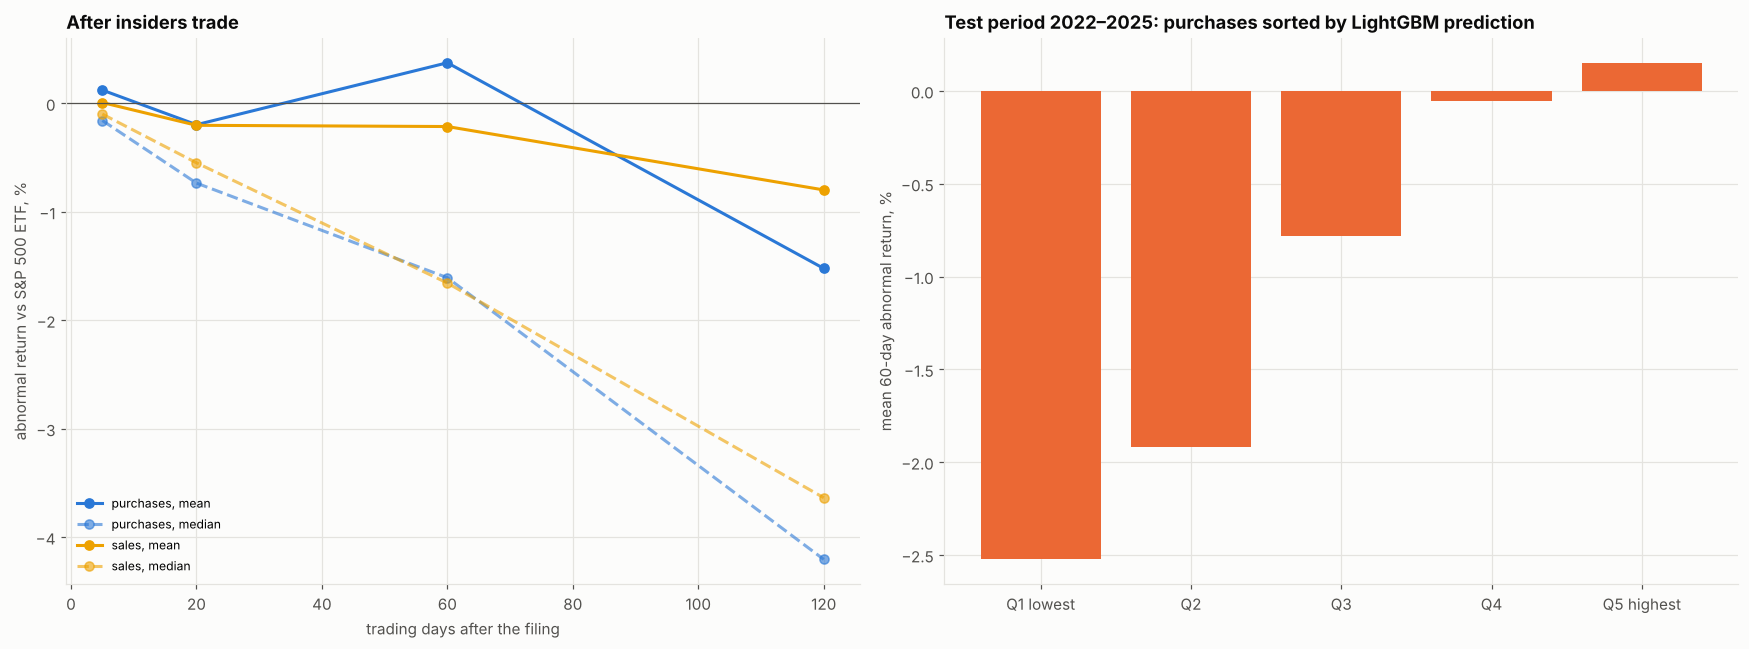

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a = ax[0]
for i, (lab, d) in enumerate([
    ("purchases", EV[EV.TRANS_CODE == "P"]),
    ("sales", EV[EV.TRANS_CODE == "S"]),
]):
    a.plot(
        HORIZONS,
        [d[f"ar_{h}"].clip(-1, 3).mean() * 100 for h in HORIZONS],
        "o-",
        color=PALETTE[i * 3],
        label=f"{lab}, mean",
    )
    a.plot(
        HORIZONS,
        [d[f"ar_{h}"].median() * 100 for h in HORIZONS],
        "o--",
        color=PALETTE[i * 3],
        alpha=0.6,
        label=f"{lab}, median",
    )
a.axhline(0, color=INK_2, lw=0.8)
a.set_xlabel("trading days after the filing")
a.set_ylabel("abnormal return vs S&P 500 ETF, %")
a.set_title("After insiders trade")
a.legend(fontsize=8)
a = ax[1]
a.bar(range(len(QS)), QS["mean"] * 100, color=PALETTE[1])
a.set_xticks(range(len(QS)), QS.index)
a.set_ylabel("mean 60-day abnormal return, %")
a.set_title(
    f"Test period {TRAIN_LAST + 1}–2025: purchases sorted by LightGBM"
    " prediction"
)
fig.tight_layout()
save_fig(fig, "01_insider_trading")
plt.show()

In [8]:
yr = B.groupby("year").agg(
    purchases=("ar_60", "size"),
    mean_AR_60=("ar_60", lambda v: v.clip(-1, 3).mean()),
)
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Insider purchases per year and mean 60-day abnormal return",
        "Mean 60-day abnormal return by role",
    ),
)
dash.add_trace(
    go.Bar(
        x=yr.index, y=yr.purchases, name="purchases", marker_color=PALETTE[0]
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=yr.index,
        y=yr.mean_AR_60 * 100,
        name="mean AR 60d (%)",
        line_color=PALETTE[3],
        yaxis="y3",
    ),
    1,
    1,
)
r_ = WHO.loc["role"]
dash.add_trace(
    go.Bar(
        x=r_.index,
        y=r_["mean"] * 100,
        marker_color=PALETTE[2],
        showlegend=False,
    ),
    1,
    2,
)
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    title="Insider trading signals from Form 4",
    yaxis3=dict(overlaying="y", side="right", title="%"),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 7. Reading the results and limitations

**The sample is large.** The SEC's Form 4 data sets for 2016 to mid-2025 contain 1.09 million open-market purchase and sale lines. Grouped by filing and kept above USD 10,000 per insider and USD 2 per share, they give 87,380 purchases and 330,633 sales by officers, directors and 10% owners in 7,933 tickers. Insiders sell almost four times as often as they buy, because their compensation is paid in shares. With prices available on Yahoo, 52,471 purchases and 209,652 sales enter the event study.

**After the filing is public, the average purchase does not beat the market.** Measured from the close of the day after the filing against the S&P 500 ETF:

- **Purchases:** a small positive abnormal return over five days (+0.12%, t = 3.1), nothing over 20 or 60 days, and −1.5% over 120 days.
- **Sales:** close to zero at every horizon.
- **Typical stock:** median abnormal returns are negative throughout (about −1.6% at 60 days), because most insider purchases are in small companies, and small caps lagged the large-cap index for most of 2016–2025.

The strong post-filing drift reported for earlier decades (Seyhun, 1986; Lakonishok and Lee, 2001) is not there for the average purchase. Markets now read Form 4s within minutes, and much of the information is priced on the filing day itself.

**Some purchases still say more than others.** Over 60 days:
- **CFO purchases** are followed by the highest abnormal returns (+3.4% on average; +3.4 points over the baseline in the regression, t = 3.7). Finance chiefs see the numbers first.
- **Cluster purchases** (+2.0% vs 0.0%) and **contrarian purchases** after a fall of more than 20% (+2.0% vs −0.1%) do better in raw averages, though not significantly once role and size are controlled for.
- **Very large purchases** above USD 1 million and **10% owners** do worst, consistent with activist or strategic buyers paying for control rather than signalling undervaluation.
- Purchases made under **10b5-1 plans**, only reported since 2023, show no positive returns, as expected for pre-scheduled trades.

**A machine-learning filter separates good from bad purchases, but not enough to beat the market.** Trained on 2016–2021 and tested on 22,067 purchases in 2022–2025, LightGBM's ranking has a rank correlation of 0.05 with the 60-day outcome. The top fifth of its predictions earned +0.1% against the market over 60 days and the bottom fifth −2.6%: a spread of 2.7 points, monotonic across quintiles. The simple rules do not help: purchases of at least USD 100,000 by CEOs or CFOs returned −1.5% and cluster purchases −1.6%, both slightly worse than the average purchase (−1.1%) in the test years. The model's value is mainly in identifying the purchases to *avoid*.

**Limitations.**
- **Survivorship:** Yahoo has prices only for tickers that still trade, so companies that were delisted or acquired after insiders bought are missing (in both directions).
- **Benchmark:** the S&P 500 ETF is a large-cap benchmark; size- and style-matched benchmarks would lower the drag on small-cap purchases, and the comparisons between groups (CFO vs CEO, top vs bottom fifth) do not depend on it.
- **Event timing:** returns start at the close of the day after the filing date; part of the reaction happens intraday on the filing date and is excluded on purpose.
- **Costs:** small companies have wide bid-ask spreads; a few percent of abnormal return can disappear in trading costs.

In [9]:
ES.to_csv(OUT_DIR / "event_study.csv")
WHO.to_csv(OUT_DIR / "purchases_by_characteristic.csv")
FILT.to_csv(OUT_DIR / "ml_filter_test.csv")
QS.to_csv(OUT_DIR / "ml_quintiles_test.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_insider_trading.png, dashboard.html, dashboard.png, event_study.csv, ml_filter_test.csv, ml_quintiles_test.csv, purchases_by_characteristic.csv


## References

- U.S. Securities and Exchange Commission. Insider Transactions Data Sets (Forms 3, 4 and 5). https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets
- Yahoo Finance. Daily prices. https://finance.yahoo.com/
- CFA Institute. *Standards of Practice Handbook*, Standard II(A) Material Nonpublic Information.
- Seyhun, H. N. (1986). Insiders' profits, costs of trading, and market efficiency. *Journal of Financial Economics*, 16(2), 189–212.
- Lakonishok, J., & Lee, I. (2001). Are insider trades informative? *Review of Financial Studies*, 14(1), 79–111.
- Cohen, L., Malloy, C., & Pomorski, L. (2012). Decoding inside information. *Journal of Finance*, 67(3), 1009–1043.
- Alldredge, D. M., & Cicero, D. C. (2015). Attentive insider trading. *Journal of Financial Economics*, 115(1), 84–101.